In [2]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Perceptron, LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

np.random.seed(42)
iris = load_iris()

In [3]:
# Part 1 — The Neuron From Scratch
# Task 1.1 — Weighted sum, step function and predict
def weighted_sum(w, x, b): return np.dot(w, x) + b
def step_function(z):      return 1 if z >= 0 else 0
def predict(w, x, b):      return step_function(weighted_sum(w, x, b))

print(predict([0.6, 0.8], [2, 3], -2))          # 1  (z = 1.6)

for x in ([1, 1], [2, 1], [0, 3]):               # slide 17 check
    print(x, "->", predict([1, -0.5], x, 0.5))   # 1, 1, 0

1
[1, 1] -> 1
[2, 1] -> 1
[0, 3] -> 0


In [4]:
# Task 1.2 — One full epoch on the AND gate, by hand
data = [(0,0,0), (0,1,0), (1,0,0), (1,1,1)]
w, b, eta, n_mistakes = np.array([0.2, -0.1]), 0.0, 0.1, 0

for x1, x2, y in data:
    x = np.array([x1, x2])
    z = weighted_sum(w, x, b)
    y_hat = step_function(z)
    e = y - y_hat
    if e != 0: n_mistakes += 1
    w = w + eta * e * x
    b = b + eta * e
    print(f"x={x}, y={y}, z={z:.2f}, y_hat={y_hat}, e={e:+d} -> w={np.round(w,2)}, b={b:.2f}")

print("Final w =", np.round(w, 2), " b =", round(b, 2), " mistakes =", n_mistakes)
print("Converged!" if n_mistakes == 0 else "Keep training.")

x=[0 0], y=0, z=0.00, y_hat=1, e=-1 -> w=[ 0.2 -0.1], b=-0.10
x=[0 1], y=0, z=-0.20, y_hat=0, e=+0 -> w=[ 0.2 -0.1], b=-0.10
x=[1 0], y=0, z=0.10, y_hat=1, e=-1 -> w=[ 0.1 -0.1], b=-0.20
x=[1 1], y=1, z=-0.20, y_hat=0, e=+1 -> w=[0.2 0. ], b=-0.10
Final w = [0.2 0. ]  b = -0.1  mistakes = 3
Keep training.


In [5]:
# Part 2 — Train a Perceptron From Scratch
# Task 2.1 — Implement train_perceptron
def train_perceptron(X, y, eta=0.1, max_epochs=100):
    X = np.asarray(X, dtype=float)
    w, b, mistakes = np.zeros(X.shape[1]), 0.0, []
    for _ in range(max_epochs):
        errors = 0
        for xi, yi in zip(X, y):
            e = yi - predict(w, xi, b)
            if e != 0:
                w = w + eta * e * xi
                b = b + eta * e
                errors += 1
        mistakes.append(errors)
        if errors == 0:          # early stop
            break
    return w, b, mistakes

X_or = [[0,0],[0,1],[1,0],[1,1]]
y_or = [0,1,1,1]
w_or, b_or, mist_or = train_perceptron(X_or, y_or)
print("w =", w_or, " b =", b_or, " mistakes/epoch =", mist_or)

w = [0.1 0.1]  b = -0.1  mistakes/epoch = [2, 2, 1, 0]


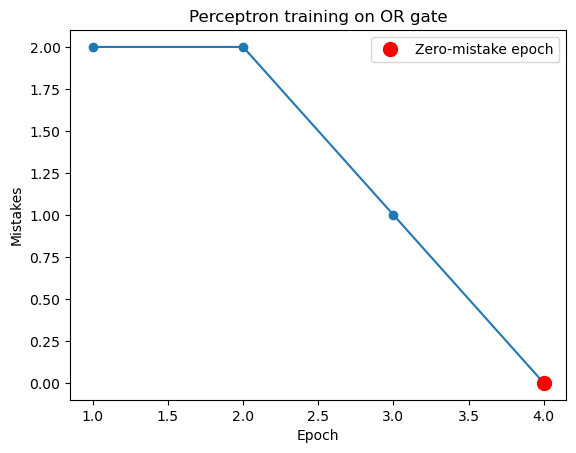

In [6]:
# Task 2.2 — Plot mistakes per epoch
epochs = range(1, len(mist_or) + 1)
plt.plot(epochs, mist_or, marker="o")
plt.plot(len(mist_or), mist_or[-1], "ro", markersize=10, label="Zero-mistake epoch")
plt.xlabel("Epoch"); plt.ylabel("Mistakes")
plt.title("Perceptron training on OR gate"); plt.legend(); plt.show()

In [6]:
# Describe the trend in one sentence.
# the mistakes fall from 2 to 0 in 4 epochs, which is fast convergence because OR is linearly separable.

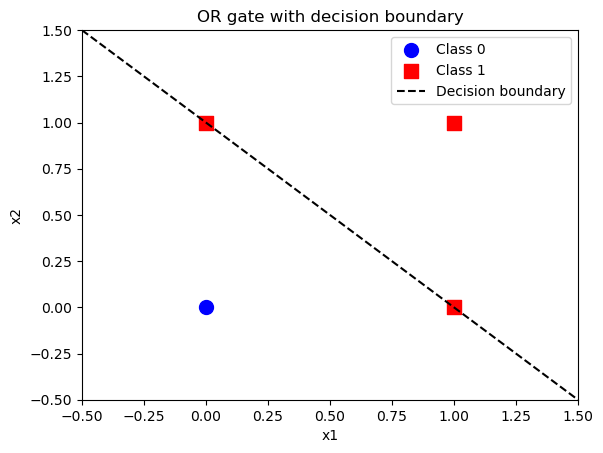

In [7]:
# Part 3 — The Decision Boundary
# Task 3.1 — Plot the OR gate with its boundary
def plot_boundary(ax, w, b, **kw):
    x_min, x_max = ax.get_xlim(); y_lo, y_hi = ax.get_ylim()
    w1, w2 = w
    if abs(w2) > 1e-12:
        x1 = np.linspace(x_min, x_max, 100)
        ax.plot(x1, -(w1 / w2) * x1 - b / w2, "k--", label="Decision boundary", **kw)
    elif abs(w1) > 1e-12:                      # w2 = 0 -> vertical line
        ax.axvline(-b / w1, color="k", linestyle="--", label="Decision boundary")
    ax.set_xlim(x_min, x_max); ax.set_ylim(y_lo, y_hi)
X = np.array(X_or); y = np.array(y_or)
fig, ax = plt.subplots()
ax.scatter(*X[y==0].T, c="blue", marker="o", s=100, label="Class 0")
ax.scatter(*X[y==1].T, c="red",  marker="s", s=100, label="Class 1")
ax.set_xlim(-0.5, 1.5); ax.set_ylim(-0.5, 1.5)
plot_boundary(ax, w_or, b_or)
ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.set_title("OR gate with decision boundary"); ax.legend()
plt.show()




In [8]:
# 3. Which side of the line is ŷ = 1? One sentence.
# the boundary is x₂ = −x₁ + 1. ŷ = 1 on the upper-right side of the line, in the direction the weight vector w = (0.1, 0.1)
# points, where w·x + b ≥ 0.

With bias   : [0.1 0.1] -0.2 epochs: 4 final mistakes: 0
Without bias: [0.1 0. ] 0.0 epochs: 100 final mistakes: 2


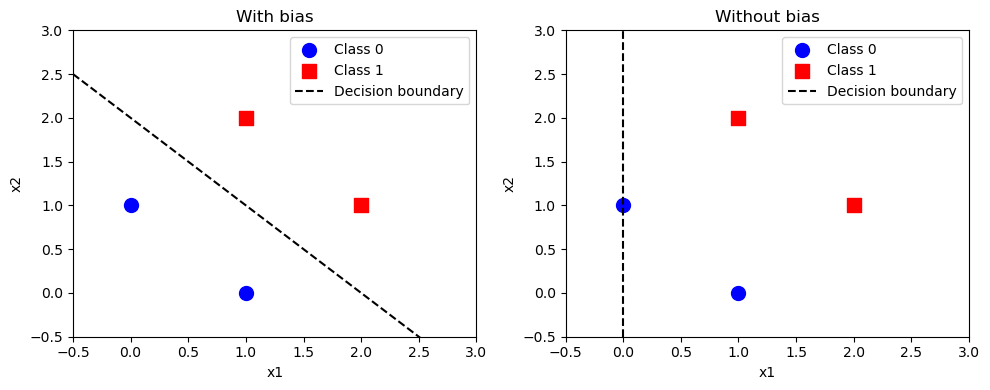

In [9]:
# Task 3.2 — With and without bias
def train_perceptron_nobias(X, y, eta=0.1, max_epochs=100):
    X = np.asarray(X, dtype=float)
    w, mistakes = np.zeros(X.shape[1]), []
    for _ in range(max_epochs):
        errors = 0
        for xi, yi in zip(X, y):
            e = yi - predict(w, xi, 0.0)
            if e != 0:
                w = w + eta * e * xi       # b stays 0
                errors += 1
        mistakes.append(errors)
        if errors == 0: break
    return w, 0.0, mistakes

X2 = np.array([[1,0],[0,1],[2,1],[1,2]]); y2 = np.array([0,0,1,1])
w_b,  b_b,  m_b  = train_perceptron(X2, y2)
w_nb, b_nb, m_nb = train_perceptron_nobias(X2, y2)
print("With bias   :", w_b, b_b, "epochs:", len(m_b), "final mistakes:", m_b[-1])
print("Without bias:", w_nb, b_nb, "epochs:", len(m_nb), "final mistakes:", m_nb[-1])

plt.figure(figsize=(10, 4))
for k, (w_, b_, t) in enumerate([(w_b, b_b, "With bias"), (w_nb, b_nb, "Without bias")], 1):
    ax = plt.subplot(1, 2, k)
    ax.scatter(*X2[y2==0].T, c="blue", marker="o", s=100, label="Class 0")
    ax.scatter(*X2[y2==1].T, c="red",  marker="s", s=100, label="Class 1")
    ax.set_xlim(-0.5, 3); ax.set_ylim(-0.5, 3)
    plot_boundary(ax, w_, b_)
    ax.set_title(t); ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.legend()
plt.tight_layout(); plt.show()

In [11]:
# 3. Did the no-bias version converge? One sentence on what removing the bias changes (slide 19).
# the with-bias version converges. The no-bias version does not converge, and its mistakes never reach 0. Without a bias the 
# boundary is forced through the origin (slide 19). Here, class 0 needs w₁ < 0 and w₂ < 0, but class 1 needs 2w₁ + w₂ ≥ 0,
# which is impossible. So the bias is what lets the boundary shift away from the origin.

Final mistakes: 4  w = [-0.1  0. ]  b = 0.0  epochs run: 100


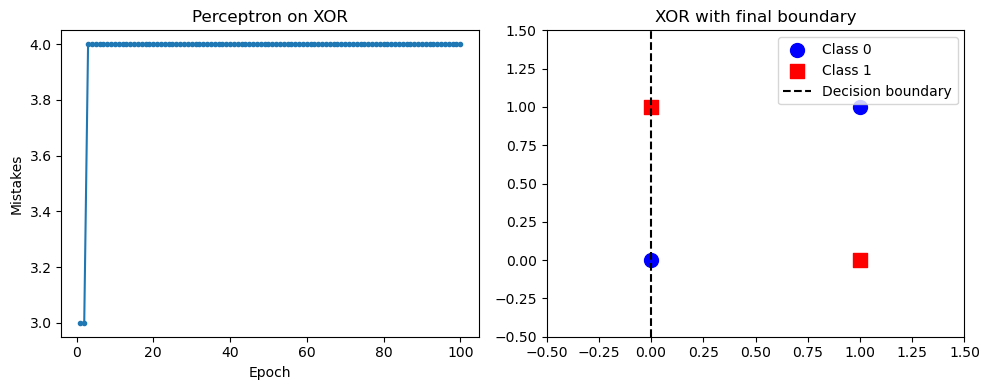

In [12]:
# Part 4 — The XOR Limitation
# Task 4.1 — Watch the perceptron fail
X_xor = np.array([[0,0],[0,1],[1,0],[1,1]]); y_xor = np.array([0,1,1,0])
w_x, b_x, m_x = train_perceptron(X_xor, y_xor, max_epochs=100)
print("Final mistakes:", m_x[-1], " w =", w_x, " b =", b_x, " epochs run:", len(m_x))

fig, axs = plt.subplots(1, 2, figsize=(10, 4))
axs[0].plot(range(1, len(m_x)+1), m_x, marker=".")
axs[0].set_xlabel("Epoch"); axs[0].set_ylabel("Mistakes"); axs[0].set_title("Perceptron on XOR")
axs[1].scatter(*X_xor[y_xor==0].T, c="blue", marker="o", s=100, label="Class 0")
axs[1].scatter(*X_xor[y_xor==1].T, c="red",  marker="s", s=100, label="Class 1")
axs[1].set_xlim(-0.5, 1.5); axs[1].set_ylim(-0.5, 1.5)
plot_boundary(axs[1], w_x, b_x)
axs[1].set_title("XOR with final boundary"); axs[1].legend()
plt.tight_layout(); plt.show()

In [13]:
# 3. Two sentences: does it ever reach zero mistakes, and why not?
# no, it never reaches zero mistakes. It runs all 100 epochs and the mistake count keeps oscillating. XOR is not linearly 
# separable, so no single straight line can put (0,1) and (1,0) on one side and (0,0) and (1,1) on the other. The weights keep
# getting pushed back and forth.

In [14]:
# Task 4.2 — Confirm no weight vector works
def check_xor(w, b):
    return (np.dot(w, [0,0]) + b <  0 and np.dot(w, [0,1]) + b >= 0 and
            np.dot(w, [1,0]) + b >= 0 and np.dot(w, [1,1]) + b <  0)

W = np.random.uniform(-5, 5, (10000, 2))
B = np.random.uniform(-5, 5, 10000)
passed = [(W[i,0], W[i,1], B[i]) for i in range(10000) if check_xor(W[i], B[i])]
print("Passing triples:", len(passed))
print("No solution found" if not passed else passed[0])

Passing triples: 0
No solution found


In [15]:
# Part 5 — scikit-learn Perceptron on Iris
# Task 5.1 — Train and evaluate
X = iris.data[:, (2, 3)]
y = (iris.target == 0).astype(int)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

clf = Perceptron(random_state=42).fit(X_tr, y_tr)
y_pred = clf.predict(X_te)
print("Accuracy:", accuracy_score(y_te, y_pred))
print(confusion_matrix(y_te, y_pred))
print(classification_report(y_te, y_pred, target_names=["Rest", "Setosa"]))
print("coef_:", clf.coef_, " intercept_:", clf.intercept_)

Accuracy: 1.0
[[30  0]
 [ 0 15]]
              precision    recall  f1-score   support

        Rest       1.00      1.00      1.00        30
      Setosa       1.00      1.00      1.00        15

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45

coef_: [[-1.3 -2.2]]  intercept_: [4.]


In [16]:
# 3. Print clf.coef_ and clf.intercept_. One sentence: which symbols from Part 1 are these?
# coef_ is the weight vector w (w₁, w₂) and intercept_ is the bias b from Part 1. Setosa is linearly separable from the other 
# classes, so expect accuracy at or near 1.0.

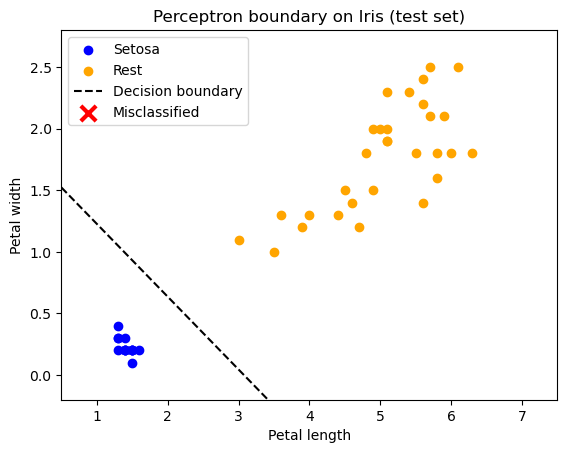

Misclassified test points: 0


In [17]:
# Task 5.2 — Visualise the learned boundary
fig, ax = plt.subplots()
ax.scatter(*X_te[y_te==1].T, c="blue",   label="Setosa")
ax.scatter(*X_te[y_te==0].T, c="orange", label="Rest")
ax.set_xlim(0.5, 7.5); ax.set_ylim(-0.2, 2.8)
plot_boundary(ax, clf.coef_[0], clf.intercept_[0])
wrong = y_pred != y_te
ax.scatter(*X_te[wrong].T, c="red", marker="x", s=120, linewidths=3, label="Misclassified", zorder=5)
ax.set_xlabel("Petal length"); ax.set_ylabel("Petal width"); ax.set_title("Perceptron boundary on Iris (test set)")
ax.legend(); plt.show()
print("Misclassified test points:", wrong.sum())

In [18]:
# 3. How many test points are misclassified? Is the boundary straight? Two sentences
# “The model misclassifies <wrong.sum()> test points (expected 0 for Setosa vs rest). Yes, the boundary is a straight line, 
# because a perceptron is a linear classifier (z = w·x + b = 0).”

In [19]:
# Task 5.3 — Effect of learning rate
rows = []
for eta in [0.001, 0.1, 10.0]:
    m = Perceptron(eta0=eta, random_state=42).fit(X_tr, y_tr)
    rows.append({"eta0": eta, "accuracy": accuracy_score(y_te, m.predict(X_te)),
                 "n_iter_": m.n_iter_, "coef_": np.round(m.coef_[0], 4), "intercept_": np.round(m.intercept_[0], 4)})
print(pd.DataFrame(rows).to_string(index=False))

  eta0  accuracy  n_iter_              coef_  intercept_
 0.001       1.0        6 [-0.0013, -0.0022]       0.004
 0.100       1.0        7     [-0.13, -0.22]       0.400
10.000       1.0        7     [-13.0, -22.0]      40.000


In [20]:
# 2. Do the predictions change? Compare the three coef_ vectors and explain what η actually does here when training starts
# from w = 0.
# the predictions, accuracy and n_iter_ are the same for all three. The coef_ vectors point in the same direction and differ
# only by a scale factor, roughly proportional to η. Training starts from w = 0, and every update is η·e·x. So η multiplies 
# all weights by the same constant, and the step function only looks at the sign of z, which does not change under a positive 
# scaling. So with zero initialisation, η only rescales w and b; it does not change the decision boundary

In [21]:
# Part 6 — Multi-Class Classification
# Task 6.1 — All three Iris classes
Xa, ya = iris.data, iris.target
Xa_tr, Xa_te, ya_tr, ya_te = train_test_split(Xa, ya, test_size=0.3, random_state=42, stratify=ya)
pcl = Perceptron(random_state=42, max_iter=1000).fit(Xa_tr, ya_tr)
yp = pcl.predict(Xa_te)
print(classification_report(ya_te, yp, target_names=iris.target_names))
print(confusion_matrix(ya_te, yp))
print("coef_ shape:", pcl.coef_.shape)   # (3, 4)

              precision    recall  f1-score   support

      setosa       0.52      1.00      0.68        15
  versicolor       0.00      0.00      0.00        15
   virginica       0.94      1.00      0.97        15

    accuracy                           0.67        45
   macro avg       0.48      0.67      0.55        45
weighted avg       0.48      0.67      0.55        45

[[15  0  0]
 [14  0  1]
 [ 0  0 15]]
coef_ shape: (3, 4)


C:\Users\M.LAPTOP\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\M.LAPTOP\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\M.LAPTOP\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [22]:
# 2. Print the classification report and confusion matrix, and clf.coef_.shape. What does each row of coef_ represent?
# Each row of coef_ is one binary perceptron (one-vs-rest): row k holds the 4 weights for “class k vs all the others”.
# 3. Which class is hardest to classify? Use the confusion matrix to explain
# Versicolor (class 1) is usually the hardest. Setosa is linearly separable, but Versicolor and Virginica overlap. Versicolor
# also sits in the middle, so one straight line cannot separate it from both sides. The confusion matrix shows its errors in the
# Versicolor row and column, with confusions against Virginica. Confirm this against your own matrix.

In [23]:
# Task 6.2 — Perceptron vs Logistic Regression
lr = LogisticRegression(random_state=42, max_iter=200).fit(Xa_tr, ya_tr)
ylr = lr.predict(Xa_te)
cmp = pd.DataFrame({
    "Model": ["Perceptron", "Logistic Regression"],
    "Accuracy": [accuracy_score(ya_te, yp), accuracy_score(ya_te, ylr)],
    "Macro-F1": [f1_score(ya_te, yp, average="macro"), f1_score(ya_te, ylr, average="macro")]})
print(cmp.to_string(index=False))

              Model  Accuracy  Macro-F1
         Perceptron  0.666667  0.549853
Logistic Regression  0.933333  0.933259


In [24]:
# Task 6.2 — Perceptron vs Logistic Regression
# logistic regression can beat the perceptron because the sigmoid is smooth and its gradient is never exactly zero. It keeps
# adjusting the weights using how confident each prediction is. The step function only says “right” or “wrong”, so it learns 
# only from outright mistakes and gives no useful signal on overlapping classes.

In [25]:
# Part 7: Graded questions
# Q1: manual update trace
# Answer: z = 0.5 − 0.6 + 0.2 = 0.1, so ŷ = 1. The target is 0, so e = −1.

# w₁ = 0.5 + 0.1(−1)(1) = 0.4
# w₂ = −0.3 + 0.1(−1)(2) = −0.5
# b = 0.2 + 0.1(−1) = 0.1

# Check: new z = 0.4 − 1.0 + 0.1 = −0.5, so ŷ = 0, which is now correct.

In [26]:
# Q2: boundary geometry
# Answer: set 0.3x₁ + 0.2x₂ − 0.4 = 0, which gives x₂ = −1.5x₁ + 2. For (1,1): z = 0.3 + 0.2 − 0.4 = 0.1 ≥ 0, so it lies on the
# ŷ = 1 side of the line (just above it) and ŷ = 1, which is correct for AND.

In [27]:
# Q3: XOR analysis

# (a) Algebra. The four constraints are:

# b < 0
# w₂ + b ≥ 0
# w₁ + b ≥ 0
# w₁ + w₂ + b < 0

# Add the middle two: w₁ + w₂ + 2b ≥ 0, so w₁ + w₂ + b ≥ −b. Since b < 0, −b > 0, so w₁ + w₂ + b > 0.
# That contradicts the last constraint, so no (w, b) satisfies all four.

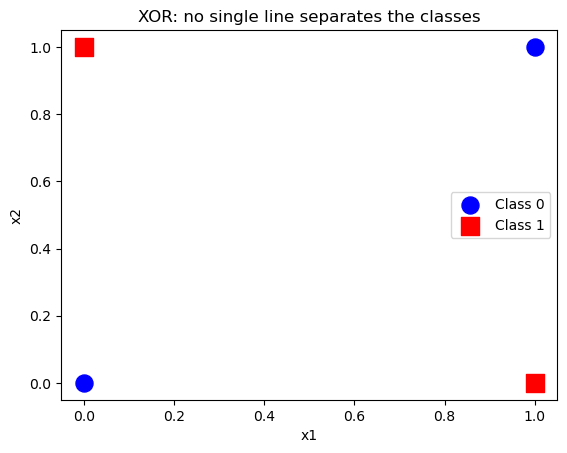

In [28]:
# b. Sketch
plt.scatter([0,1], [0,1], c="blue", marker="o", s=150, label="Class 0")
plt.scatter([0,1], [1,0], c="red",  marker="s", s=150, label="Class 1")
plt.xlabel("x1"); plt.ylabel("x2"); plt.title("XOR: no single line separates the classes")
plt.legend(); plt.show()

In [29]:
# The two classes sit on the opposite diagonals of the square, so any line that separates one pair of diagonal points cuts
# through or misses the other pair.

In [30]:
# (c) Add a hidden layer (a multi-layer perceptron). One hidden unit computes OR and another computes NAND, and the output
# unit computes AND of them. Quick demo:
def xor_mlp(x):
    h1 = predict([1, 1], x, -0.5)      # OR
    h2 = predict([-1, -1], x, 1.5)     # NAND
    return predict([1, 1], [h1, h2], -1.5)  # AND
print([xor_mlp(x) for x in X_xor])     # [0, 1, 1, 0]

[0, 1, 1, 0]


In [31]:
# Q4: Iris extension (features 0, 2, 3)
X3 = iris.data[:, [0, 2, 3]]
X3_tr, X3_te, y3_tr, y3_te = train_test_split(X3, y, test_size=0.3, random_state=42, stratify=y)
c3 = Perceptron(random_state=42).fit(X3_tr, y3_tr)
p3 = c3.predict(X3_te)
print("2 features -> acc:", accuracy_score(y_te, y_pred), " macro-F1:", f1_score(y_te, y_pred, average="macro"))
print("3 features -> acc:", accuracy_score(y3_te, p3),  " macro-F1:", f1_score(y3_te, p3, average="macro"))


2 features -> acc: 1.0  macro-F1: 1.0
3 features -> acc: 1.0  macro-F1: 1.0


In [32]:
# “With features (0,2,3) accuracy = <x> and macro-F1 = <y>, compared with <a> and <f> for features (2,3). The extra feature does
# not help: Setosa is already linearly separable on petal length and width, so the 2-feature model is already at or near perfect
# and has no room to improve.” If your numbers do differ, state the difference and say whether it is meaningful on only 45 test
# points.

Hand-built: acc=0.817, epochs=100, w=[ 0.30703238 -0.25631318], b=0.200
sklearn   : acc=0.667, epochs=6, w=[2.28133191 0.57972588], b=2.000


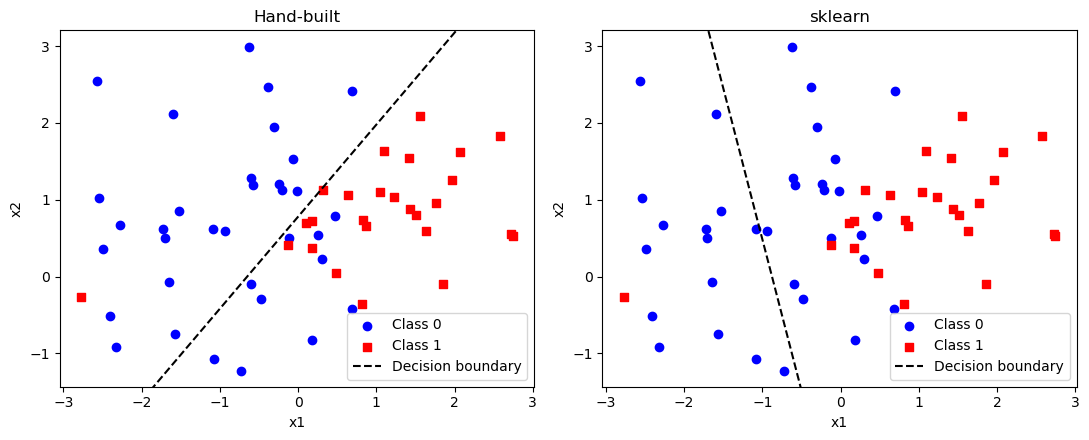

In [33]:
# Q5: synthetic data
Xs, ys = make_classification(n_samples=200, n_features=2, n_redundant=0,
                             n_clusters_per_class=1, random_state=42)
Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(Xs, ys, test_size=0.3, random_state=42)

w_h, b_h, m_h = train_perceptron(Xs_tr, ys_tr, eta=0.1, max_epochs=100)
yh = np.array([predict(w_h, xi, b_h) for xi in Xs_te])
sk = Perceptron(random_state=42).fit(Xs_tr, ys_tr)
ysk = sk.predict(Xs_te)

print(f"Hand-built: acc={accuracy_score(ys_te, yh):.3f}, epochs={len(m_h)}, w={w_h}, b={b_h:.3f}")
print(f"sklearn   : acc={accuracy_score(ys_te, ysk):.3f}, epochs={sk.n_iter_}, w={sk.coef_[0]}, b={sk.intercept_[0]:.3f}")

fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (w_, b_, t) in zip(axs, [(w_h, b_h, "Hand-built"), (sk.coef_[0], sk.intercept_[0], "sklearn")]):
    ax.scatter(*Xs_te[ys_te==0].T, c="blue", marker="o", label="Class 0")
    ax.scatter(*Xs_te[ys_te==1].T, c="red",  marker="s", label="Class 1")
    plot_boundary(ax, w_, b_)
    ax.set_title(t); ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.legend()
plt.tight_layout(); plt.show()